# Antenna Tilt — 2b: the joint tilt objective for two sectors

Stage 2a showed that one sector's tilt changes what its neighbour's users receive. Stage 2b turns that
into an objective $J(t_1,t_2)$ over a fixed region with demand, and asks: which pair of tilts is preferred,
how much does the choice matter, and how far do the answers depend on the modelling choices behind them?
New logic lives in `telecomopt.coverage` (`sample_rectangle`, `sweep_metrics`), `telecomopt.network`
(`power_table`, `se_cube`), `telecomopt.sweep` (`tilt_sweep`) and `telecomopt.plots`.

**The story in brief.**
1. We first restrict both antennas to 0–10°. Both objectives prefer the upper corner, $(10°,10°)$, so this
   experiment identifies the best *permitted* setting but leaves open whether larger tilts perform better.
2. Expanding the search to 0–20° reveals two strategies. Equal moderate tilts maximise the average link
   quality. Strongly unequal tilts let one sector dominate most locations and improve the lower tail.
3. Which strategy is preferred depends on which users we include (the region) and on the antenna-pattern
   assumptions (the elevation floor). Section 6c maps where the good and bad links lie.

This is a **link-quality** study: it computes each location's spectral efficiency $C_u$, not how much of a
sector's resources each user receives (see Section 8).

**How to read the main outputs.**

| Output | What the reader should understand |
|---|---|
| Symmetric heatmaps | Swapping the sector labels leaves the aggregate result unchanged, so every unequal optimum has a mirror twin. Equal tilts are not required. |
| Maximum at $(10°,10°)$ | The best *sampled* setting inside the baseline constraint; not evidence that 10° is a natural physical optimum. |
| Mean maximum near $(12°,12°)$ | The best average SE among the sampled configurations for this scenario. |
| Lower-tail maximum near $(5.5°,18.5°)$ | Unequal service footprints raise the quality cutoff for the weakest 5 % of the demand. |
| Several nearly equivalent unequal pairs | The broad strategy is more reliable than the precise preferred angles. |
| Changes with the region width | Changing where the users are changes which configuration is desirable. |

**Setup (decision log D11, D12).**
- *Layout:* two sites facing each other, ISD 500 m — sector 1 at $(0,0)$ facing $+x$, sector 2 at $(500,0)$
  facing $-x$; same resource, simultaneous transmission, strongest-power association, the other sector
  contributes interference (D11).
- *Region and demand:* $x\in[0,500]$ m, $y\in[-250,250]$ m, **uniform** demand, cells within $d_{\min}=35$ m of
  either mast get zero weight (D09). The region is a modelling choice, not a reference constant.
- *Grid:* cell-centred, $100\times100$ cells of 5 m, so no sample lies on the tie line $x=250$.
- *Metrics (1b definitions, unchanged):* with weights $p_i\propto\rho_i\,\Delta A_i$ and
  $C_i=\log_2(1+\mathrm{SINR}_i)$, the **mean SE** $\sum_i p_iC_i$ (a capacity *proxy*) and the **5th-percentile
  SE** (the threshold below which 5 % of the demand-weighted area lies — a boundary value, not the mean of
  the tail).
- *Tilts:* **electrical tilt only; mechanical tilt is 0 for both sectors.** In the forward vertical plane the
  total downtilt is $t_{\mathrm{total}}=\alpha_m+\alpha_e$, measured below the horizontal, so with $\alpha_m=0$
  our axes are also the total tilts of the beam on boresight. The baseline is 0–10° in 0.5° steps (21 values
  per sector, 441 pairs), *informed by* the measured electrical-pattern set $\{0,\dots,10\}°$ that [E] uses to
  validate its pattern model; it is not the interval over which [E] optimises (that paper computes coverage
  for $\alpha_e\in[-5,15]°$ and $\alpha_m\in[-5,20]°$, with *identical* settings at every site). The 0–20°
  range of Section 6 is an *extended electrical-tilt exploration*. Our axes (the electrical tilts of two
  different sectors) are not the axes of the electrical-versus-mechanical figures of [E], so our heatmaps
  are not reproductions of them, and relabelling 0–20° electrical results as electrical-plus-mechanical
  would be wrong: off boresight the two tilt types give different patterns. Whether any antenna can realise a
  given setting is a separate hardware question (D12, D13).
- Everything is **deterministic** (median link). Shadow fading and the uncertainty analysis are a separate,
  pending layer (D06).

**Hypotheses recorded before the sweep (D12).** *H1:* where the map is interference-limited,
$\mathrm{SE}\approx\log_2(1+S_{\max}/S_{\min})$ depends on the power *ratio* of the two sectors, so an
unequal-tilt optimum is possible, with an equally good mirror twin. *H2:* the 5th percentile is set near the
association boundary, so it is more sensitive to the geometry of that boundary than the mean is.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from telecomopt.rf import RFParams, to_db, elevation_angle_deg
from telecomopt.network import Sector, sinr_field, on_pattern_parabola
from telecomopt.coverage import non_dominated, weighted_percentile, weighted_cdf
from telecomopt.sweep import tilt_sweep
from telecomopt.plots import tilt_heatmap, field_map, grid_image

In [2]:
p = RFParams()                                   # [E] Table I constants
ISD = 500.0                                      # modelling choice (D11)
sectors = [Sector(0.0, 0.0, 0.0), Sector(ISD, 0.0, 180.0)]
FEASIBLE = np.arange(0.0, 10.0 + 1e-9, 0.5)      # baseline interval informed by [E]'s measured set (D12): 21 values, 441 pairs
EXPLORE = np.arange(0.0, 20.0 + 1e-9, 0.5)       # extended electrical-tilt exploration (mechanical tilt 0)
print(f"{len(FEASIBLE)} baseline tilt candidates per sector -> {len(FEASIBLE) ** 2} pairs; "
      f"{len(EXPLORE)} exploration tilts -> {len(EXPLORE) ** 2} pairs")

21 baseline tilt candidates per sector -> 441 pairs; 41 exploration tilts -> 1681 pairs


## 1. The baseline sweep and the symmetry check

A sector's received power depends only on **its own** tilt. `tilt_sweep` therefore computes one power table
per sector (21 tilts $\times$ 10 000 points), forms every pair by stacking one row of each into the
spectral-efficiency cube (21 $\times$ 21 $\times$ 10 000), and applies the 1b metrics to each pair — about
four seconds in place of a field evaluation per pair.

**First correctness check.** Region, grid, demand and tower floors are all mirror-symmetric about $x=250$,
so $J(t_1,t_2)=J(t_2,t_1)$ must hold for both objectives. This does *not* require the optimum to have equal
tilts: an unequal optimum would simply have an equally good reflected twin.

In [3]:
base = tilt_sweep(sectors, [FEASIBLE, FEASIBLE])        # region [0,500] x [-250,250], 100 x 100 cells, uniform demand
mean_se, p5_se = base["mean_se"], base["p5_se"]
print("SE cube:", base["cube"].shape, "(t1, t2, point)")
print(f"valid area {base['weights'].sum():,.0f} m^2 of {ISD * 500.0:,.0f} m^2 (the rest is inside the 35 m tower floors)")
print("max |J(t1,t2) - J(t2,t1)|  mean SE:", np.abs(mean_se - mean_se.T).max(), "  5th-pct SE:", np.abs(p5_se - p5_se.T).max())

SE cube: (21, 21, 10000) (t1, t2, point)
valid area 246,100 m^2 of 250,000 m^2 (the rest is inside the 35 m tower floors)
max |J(t1,t2) - J(t2,t1)|  mean SE: 1.3322676295501878e-15   5th-pct SE: 7.105427357601002e-15


## 2. The landscape inside the baseline interval (0–10°)

Heatmaps of both objectives over $(t_1,t_2)$ (star = maximum, dotted line = equal tilts), then the maxima,
the equal-tilt line, the **effect size** of choosing differently, and the non-dominated set. The Pareto
front is read on $t_1\le t_2$ so each mirror pair is counted once.
Each pixel is one pair of tilts and its colour is the objective value over the whole region. The pictures
are symmetric about the dotted diagonal because swapping the sector labels changes nothing.


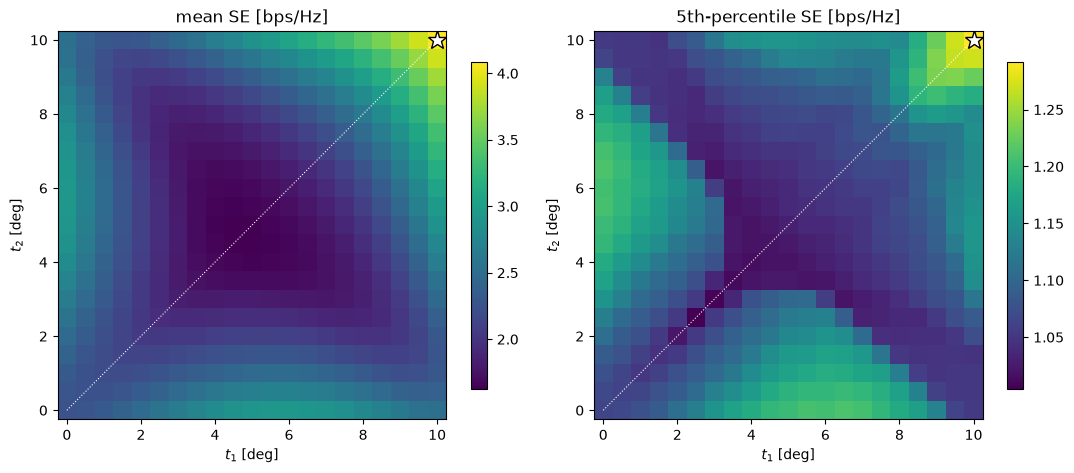

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, J, name in zip(axes, [mean_se, p5_se], ["mean SE [bps/Hz]", "5th-percentile SE [bps/Hz]"]):
    fig.colorbar(tilt_heatmap(ax, FEASIBLE, FEASIBLE, J, name), ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

In [5]:
for name, J in [("mean SE", mean_se), ("5th-pct SE", p5_se)]:
    i, j = np.unravel_index(np.argmax(J), J.shape)
    d = np.diag(J)
    print(f"{name:11s} max {J.max():.3f} at (t1, t2) = ({FEASIBLE[i]}, {FEASIBLE[j]})  |  "
          f"equal-tilt line: min {d.min():.3f} at {FEASIBLE[np.argmin(d)]} deg, max {d.max():.3f} at {FEASIBLE[np.argmax(d)]} deg")
print(f"pairs within 1 % of the mean-SE maximum: {(mean_se >= 0.99 * mean_se.max()).sum()};  of the 5th-pct maximum: {(p5_se >= 0.99 * p5_se.max()).sum()}")

mean SE     max 4.088 at (t1, t2) = (10.0, 10.0)  |  equal-tilt line: min 1.630 at 4.5 deg, max 4.088 at 10.0 deg
5th-pct SE  max 1.292 at (t1, t2) = (10.0, 10.0)  |  equal-tilt line: min 1.005 at 2.5 deg, max 1.292 at 10.0 deg
pairs within 1 % of the mean-SE maximum: 1;  of the 5th-pct maximum: 1


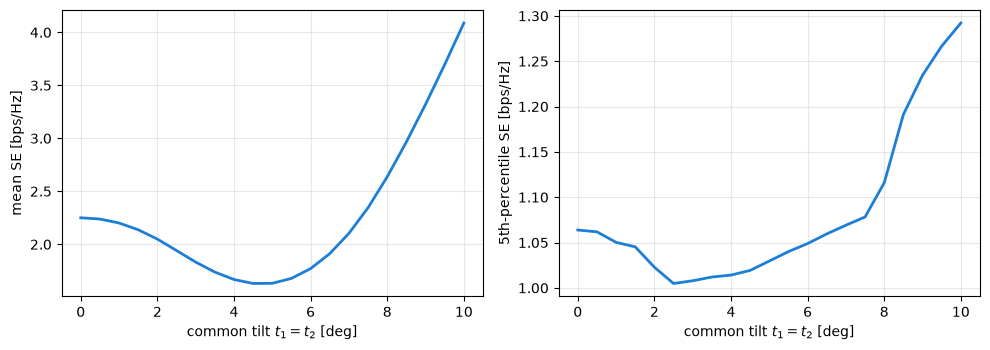

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, J, name in zip(axes, [mean_se, p5_se], ["mean SE [bps/Hz]", "5th-percentile SE [bps/Hz]"]):
    ax.plot(FEASIBLE, np.diag(J), color="#1c7ed6", lw=2)
    ax.set_xlabel("common tilt $t_1=t_2$ [deg]"); ax.set_ylabel(name); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [7]:
best = {"mean SE": mean_se.max(), "5th-pct SE": p5_se.max()}
for t1, t2 in [(10.0, 10.0), (9.0, 9.0), (8.0, 8.0), (5.0, 5.0), (10.0, 9.5), (10.0, 8.0)]:
    i, j = np.searchsorted(FEASIBLE, [t1, t2])
    print(f"({t1:4.1f}, {t2:4.1f}):  mean SE {mean_se[i, j]:.3f} ({mean_se[i, j] / best['mean SE'] - 1:+6.1%} vs best)   "
          f"5th-pct SE {p5_se[i, j]:.3f} ({p5_se[i, j] / best['5th-pct SE'] - 1:+6.1%} vs best)")

(10.0, 10.0):  mean SE 4.088 ( +0.0% vs best)   5th-pct SE 1.292 ( +0.0% vs best)
( 9.0,  9.0):  mean SE 3.321 (-18.8% vs best)   5th-pct SE 1.235 ( -4.5% vs best)
( 8.0,  8.0):  mean SE 2.637 (-35.5% vs best)   5th-pct SE 1.116 (-13.6% vs best)
( 5.0,  5.0):  mean SE 1.632 (-60.1% vs best)   5th-pct SE 1.030 (-20.3% vs best)
(10.0,  9.5):  mean SE 3.900 ( -4.6% vs best)   5th-pct SE 1.270 ( -1.7% vs best)
(10.0,  8.0):  mean SE 3.459 (-15.4% vs best)   5th-pct SE 1.142 (-11.6% vs best)


In [8]:
half = np.triu(np.ones(mean_se.shape, dtype=bool))       # t1 <= t2: each mirror pair counted once
front = non_dominated(mean_se[half], p5_se[half])
i_h, j_h = np.nonzero(half)
print(f"{front.sum()} non-dominated pair(s) out of {front.size} (t1 <= t2):",
      [(float(FEASIBLE[i_h[k]]), float(FEASIBLE[j_h[k]])) for k in np.nonzero(front)[0]])

1 non-dominated pair(s) out of 231 (t1 <= t2): [(10.0, 10.0)]


**Reading the landscape** (this region, uniform demand, $100\times100$ grid, 0.5° steps).

- **Both objectives are maximised at $(t_1,t_2)=(10°,10°)$, the edge of the interval.** The optimum is
  *constraint-active*: within the assumed 0–10° interval the model prefers more downtilt than the interval offers, so
  the unconstrained optimum is not located here (Section 6 looks beyond).
- **It is not a plateau.** Only one of the 441 pairs is within 1 % of either maximum, unlike the
  single-sector case of 1b (D10). Moving from $(8°,8°)$ to $(10°,10°)$ raises the mean SE from 2.64 to
  4.09 bps/Hz ($+55\,\%$) and the 5th-percentile SE from 1.12 to 1.29 bps/Hz ($+16\,\%$); the pair $(8°,8°)$,
  at the low end of the single-sector 1b optimum range (8–9.5°), costs 36 % of mean SE and 14 % of 5th-percentile
  SE relative to the best pair.
- **The equal-tilt line is not monotone:** mean SE falls from 2.25 bps/Hz at 0° to a minimum of 1.63 at 4.5°
  before rising to 4.09 at 10°; the 5th percentile has its minimum at 2.5°. "More downtilt" does not
  uniformly help — the rise only starts at moderate tilts.
- **Unequal tilts do not help inside the interval.** The best unequal pair, $(10°,9.5°)$, is $4.6\,\%$ lower
  in mean SE and $1.7\,\%$ lower in 5th-percentile SE than the equal pair. The 5th-percentile map
  does show a second, lower ridge of strongly unequal pairs (one sector near 0–2°, the other near 5–8°; up to
  1.21 bps/Hz at $(0°,6.5°)$, with a mean SE of only 2.92) — the start of the unequal structure of Section 6,
  still below the edge value of 1.29.
- **No trade-off between the objectives here:** $(10°,10°)$ is the only non-dominated pair, so the two
  objectives agree and nothing remains to trade off in this range.

## 3. Why equal downtilt helps (H1: the power ratio)

At a ground point seen from sector 1 at depression angle $\beta_1$ and from sector 2 at $\beta_2$, with both
tilted to the same $t$ and the point inside both main lobes, Eq. 4 of [E] gives an elevation-gain difference
$$G_{\mathrm{el},1}-G_{\mathrm{el},2}=-\frac{12}{\mathrm{HPBW}^2}\Big[(\beta_1-t)^2-(\beta_2-t)^2\Big]
=\frac{12(\beta_1-\beta_2)(2t-\beta_1-\beta_2)}{\mathrm{HPBW}^2}.$$
Distance and azimuth do not depend on $t$. Write $\Delta_{\mathrm{dB}}=10\log_{10}(S_1/S_2)$ for the signed power
difference of the two sectors at the point. With equal tilts and both sectors on the parabola,
$$\frac{\mathrm{d}\Delta_{\mathrm{dB}}}{\mathrm{d}t}=\frac{24\,(\beta_1-\beta_2)}{\mathrm{HPBW}^2}\ \text{dB per degree}.$$
Where interference dominates noise, $\mathrm{SINR}_{\mathrm{dB}}\approx|\Delta_{\mathrm{dB}}|$, so what matters is the
*absolute* gap. For $\Delta_{\mathrm{dB}}\ne0$,
$$\frac{\mathrm{d}|\Delta_{\mathrm{dB}}|}{\mathrm{d}t}=\operatorname{sgn}(\Delta_{\mathrm{dB}})\,\frac{24\,(\beta_1-\beta_2)}{\mathrm{HPBW}^2}.$$
Raising both tilts therefore widens the gap only where $\operatorname{sgn}(\Delta_{\mathrm{dB}})(\beta_1-\beta_2)>0$:
the sector that is already stronger must also be the one that sees the point at the steeper angle. That is
usually the nearer sector, but path loss and elevation gain can disagree. **Conditions:** (i) equal tilts;
(ii) both sectors on their elevation parabola (not on the $-17$ dB floor) and the overall pattern not clipped at
$\mathrm{SLL}_0$; (iii) for the SINR reading only, noise negligible against the interference. The derivative of
$\Delta_{\mathrm{dB}}$ itself needs only (i) and (ii).

The derivative gives the *local* direction of change. For a finite step $h=t_b-t_a$ over which neither pattern is
clipped, $\Delta_{\mathrm{dB}}$ is exactly linear in $t$: with $k=24(\beta_1-\beta_2)/\mathrm{HPBW}^2$,
$$\Delta_b=\Delta_a+kh,\qquad |\Delta_b|>|\Delta_a|\iff kh\,(2\Delta_a+kh)>0 .$$
The two can disagree: a point that starts moving towards equal power can cross it and end the step with a larger
gap than it began with.

The first check fits the slope of $\Delta_{\mathrm{dB}}$ against the common tilt at three points on the line
between the sites. Those points have $\Delta_{\mathrm{dB}}>0$ and $\beta_1>\beta_2$, so the sign condition holds
there automatically; a second cell therefore tests the sign rule over the whole map.


In [9]:
t_common = np.arange(4.0, 12.01, 0.5)             # both sectors at the same tilt, inside the main lobe at these points
for x0 in (150.0, 200.0, 240.0):                  # probe points on the axis between the sites (y = 0)
    ratio_db = np.array([np.subtract(*to_db(sinr_field(np.array([x0]), np.array([0.0]), sectors, [t, t], params=p)["powers"][:, 0]))
                         for t in t_common])      # S_1 - S_2 in dB at this point
    b1, b2 = elevation_angle_deg(x0, p), elevation_angle_deg(ISD - x0, p)
    print(f"x = {x0:3.0f} m: beta_1 = {b1:5.2f}, beta_2 = {b2:5.2f} deg; fitted slope of S1 - S2 = {np.polyfit(t_common, ratio_db, 1)[0]:.2f} dB/deg, "
          f"predicted 24 (beta_1 - beta_2) / HPBW^2 = {24 * (b1 - b2) / p.hpbw_el ** 2:.2f} dB/deg")

x = 150 m: beta_1 = 10.76, beta_2 =  4.66 deg; fitted slope of S1 - S2 = 3.47 dB/deg, predicted 24 (beta_1 - beta_2) / HPBW^2 = 3.47 dB/deg
x = 200 m: beta_1 =  8.11, beta_2 =  5.43 deg; fitted slope of S1 - S2 = 1.52 dB/deg, predicted 24 (beta_1 - beta_2) / HPBW^2 = 1.52 dB/deg
x = 240 m: beta_1 =  6.77, beta_2 =  6.26 deg; fitted slope of S1 - S2 = 0.29 dB/deg, predicted 24 (beta_1 - beta_2) / HPBW^2 = 0.29 dB/deg


In [10]:
xg, yg = base["x"], base["y"]
wg = base["weights"] / base["weights"].sum()
beta1 = np.array([elevation_angle_deg(d, p) for d in np.hypot(xg, yg)])          # depression angle seen from each mast
beta2 = np.array([elevation_angle_deg(d, p) for d in np.hypot(xg - ISD, yg)])
k = 24.0 * (beta1 - beta2) / p.hpbw_el ** 2                                       # d Delta_dB / dt where unclipped
print("whole-map check, both sectors raised together from t_a to t_b (area-weighted shares of the unclipped part):")
for t_a, t_b in [(4.0, 5.0), (8.0, 10.0), (11.0, 12.0)]:
    f_a = sinr_field(xg, yg, sectors, [t_a, t_a], params=p)
    f_b = sinr_field(xg, yg, sectors, [t_b, t_b], params=p)
    d_a = to_db(f_a["powers"][0]) - to_db(f_a["powers"][1])                       # Delta_dB = S1 - S2
    d_b = to_db(f_b["powers"][0]) - to_db(f_b["powers"][1])
    lobe = np.all([on_pattern_parabola(xg, yg, s, t, p) for s in sectors for t in (t_a, t_b)], axis=0)   # condition (ii)
    h = t_b - t_a
    widened = np.abs(d_b) > np.abs(d_a)
    exact = np.isclose(d_b, d_a + k * h, atol=1e-9)                                  # finite step: Delta_b = Delta_a + k h
    predicted = k * h * (2 * d_a + k * h) > 0                                        # |Delta_b| > |Delta_a|  <=>  kh(2 Delta_a + kh) > 0
    initially = np.sign(d_a) * k > 0                                                  # derivative at t_a: gap starts to widen
    sinr_up = f_b["se"] > f_a["se"]
    w_lobe = wg * lobe / wg[lobe].sum()                                              # weights renormalised to the unclipped part
    print(f"  {t_a:4.1f} -> {t_b:4.1f} deg: unclipped {wg[lobe].sum():5.1%} of the area | Delta_b = Delta_a + k h on {w_lobe[exact].sum():6.1%} | "
          f"gap widens on {w_lobe[widened].sum():6.1%} (finite-step relation agrees on {w_lobe[predicted == widened].sum():6.1%}) | "
          f"widening at t_a on {w_lobe[initially].sum():6.1%} | SE rises on {w_lobe[sinr_up].sum():6.1%}; on the whole map SE rises on {wg[sinr_up].sum():6.1%}")

whole-map check, both sectors raised together from t_a to t_b (area-weighted shares of the unclipped part):
   4.0 ->  5.0 deg: unclipped 76.1% of the area | Delta_b = Delta_a + k h on 100.0% | gap widens on  66.2% (finite-step relation agrees on 100.0%) | widening at t_a on  53.3% | SE rises on  66.2%; on the whole map SE rises on  61.4%
   8.0 -> 10.0 deg: unclipped 87.9% of the area | Delta_b = Delta_a + k h on 100.0% | gap widens on 100.0% (finite-step relation agrees on 100.0%) | widening at t_a on  99.0% | SE rises on 100.0%; on the whole map SE rises on 100.0%
  11.0 -> 12.0 deg: unclipped 41.7% of the area | Delta_b = Delta_a + k h on 100.0% | gap widens on 100.0% (finite-step relation agrees on 100.0%) | widening at t_a on 100.0% | SE rises on  99.8%; on the whole map SE rises on  77.6%


**Reading the check.** On the axis the fitted slopes (3.47, 1.52 and 0.29 dB/°) match the prediction to the
printed precision, and the slope shrinks to nearly zero at 240 m, close to the tie line. The whole-map cell checks
the derivation where three points cannot:

- **The finite-step relation is exact.** On every unclipped cell $\Delta_b=\Delta_a+kh$ holds, and the criterion
  $kh(2\Delta_a+kh)>0$ agrees with the computed widening in 100 % of them, for all three steps.
- **8° → 10°:** the gap widens in every unclipped cell (87.9 % of the area) and SE rises in every cell of the map.
- **11° → 12°:** the gap widens in every unclipped cell (41.7 % of the area), but SE rises in 99.8 % of them, not
  all: where interference is not overwhelmingly larger than noise, a wider gap is not quite a better SINR. On the
  whole map SE rises in 77.6 % of the area.
- **4° → 5°:** the gap widens in only 66.2 % of the unclipped part, while the derivative at 4° points towards
  widening in only 53.3 % — the difference is the cells that cross equal power during the step. At small tilts,
  raising both tilts helps some locations and hurts others. This is consistent with the non-monotone equal-tilt
  line of Section 2 (dip near 4.5°); it does not prove it.

**H1, first part (SE depends on the power ratio): supported** by this mechanism check, under the stated
conditions. **H1, second part (an unequal-tilt optimum exists):** *not* found inside the baseline interval at
this region size (Section 2); it appears in the extended exploration (Section 6) and at a wider region
(Section 5).


## 4. Where the worst 5 % live (H2)

If the 5th percentile is set by the association boundary, the points at or below it should lie close to the
equal-power line $|S_1-S_2|=0$. A fair test needs a **base rate**: how much of the area is that close to the
boundary anyway? At $(10°,10°)$ the table compares, for bands of $|S_1-S_2|$ in dB, the share of the whole
demand-weighted area with the share of the *worst-5 %* weight. The interference-to-noise ratio is printed
first to check the interference-limited regime at this tilt pair.

In [11]:
t_star = np.searchsorted(FEASIBLE, 10.0)
f = sinr_field(base["x"], base["y"], sectors, [10.0, 10.0], params=p)
w = base["weights"] / base["weights"].sum()
dS = np.abs(to_db(f["powers"][0]) - to_db(f["powers"][1]))        # |S1 - S2| [dB]: 0 on the association boundary
worst = (f["se"] <= p5_se[t_star, t_star]) & (w > 0)               # points at or below the 5th-percentile threshold
I_over_N = to_db(f["powers"].min(axis=0)) - p.n0_dbm              # interference-to-noise: the weaker sector is the interferer
print(f"I/N over the valid region at (10,10): min {I_over_N[w > 0].min():.1f} dB")
for band in (1.0, 3.0, 6.0):
    print(f"|S1 - S2| < {band:.0f} dB:  {w[dS < band].sum():5.1%} of the demand-weighted area, {w[worst & (dS < band)].sum() / w[worst].sum():6.1%} of the worst-5 % weight")

I/N over the valid region at (10,10): min 16.8 dB
|S1 - S2| < 1 dB:   3.0% of the demand-weighted area,  60.5% of the worst-5 % weight
|S1 - S2| < 3 dB:   9.7% of the demand-weighted area, 100.0% of the worst-5 % weight
|S1 - S2| < 6 dB:  22.3% of the demand-weighted area, 100.0% of the worst-5 % weight


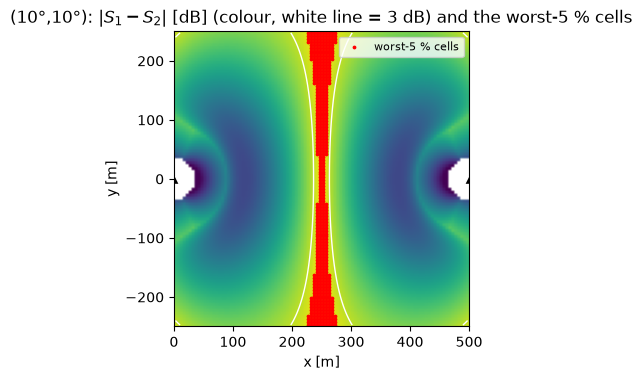

worst-5 % cells: x from 227.5 to 272.5 m, |y| up to 248 m; share of the demand-weighted area within 22.5 m of the tie line x = 250: 10.2%


In [12]:
valid = base["weights"] > 0
NX = NY = 100                                                         # the baseline grid of tilt_sweep
EXTENT = (0.0, ISD, -250.0, 250.0)
MASTS = [(s.x, s.y) for s in sectors]
fig, ax = plt.subplots(figsize=(7.4, 3.9))
field_map(ax, dS, NX, NY, EXTENT, valid, MASTS, cmap="viridis_r", vmin=0, vmax=30)
ax.contour(grid_image(dS, NX, NY, valid), levels=[3.0], colors="white", linewidths=1.0, origin="lower", extent=EXTENT)
ax.scatter(base["x"][worst], base["y"][worst], s=3, c="red", label="worst-5 % cells")
ax.set(xlabel="x [m]", ylabel="y [m]", title="(10°,10°): $|S_1-S_2|$ [dB] (colour, white line = 3 dB) and the worst-5 % cells")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()
print(f"worst-5 % cells: x from {base['x'][worst].min():.1f} to {base['x'][worst].max():.1f} m, |y| up to {np.abs(base['y'][worst]).max():.0f} m; "
      f"share of the demand-weighted area within 22.5 m of the tie line x = 250: {w[np.abs(base['x'] - 250) <= 22.5].sum():.1%}")

**Reading the table and map (at $(10°,10°)$ only).** The whole region is interference-limited (I/N never drops
below the printed minimum, far above 0 dB). The table measures closeness in **received power**, not distance:
all of the worst-5 % weight has the two sectors within 3 dB of each other, although that band holds only
9.7 % of the area; within 1 dB it still holds 60.5 % of the worst-5 % weight against 3.0 % of the area. So the
weakest locations are those where the serving and the strongest interfering power are similar. The map
shows where those locations are: at this pair every worst-5 % cell lies in a narrow strip, $x\in[227.5,272.5]$ m (the full
range, not percentiles), around the tie line — a strip that is about 10 % of the weighted area. **H2 is supported at this tilt pair.** It was not
tested at other tilt pairs here; Section 6c shows that at the unequal optimum the lower tail is **not** only the
association boundary.


## 5. Numerical stability and sensitivity to the region (one variable at a time)

*Grid refinement* changes only the number of cells (tilt step, region and tilts fixed). *Region size* changes
only the half-width $a$ of the strip in $y$, keeping the cell size at 5 m. The grid check is stability
evidence for the numbers; the region check is a different thing — it measures how much the answer depends on
a modelling choice. The $\gamma=2$ served fraction (Section 7) is included in the grid check.

In [13]:
print("grid refinement (tilt step and region fixed):")
for n in (50, 100, 200):
    s = tilt_sweep(sectors, [FEASIBLE, FEASIBLE], nx=n, ny=n)
    sf2 = (s["cube"][-1, -1] >= 2.0) @ s["weights"] / s["weights"].sum()
    print(f"  {n:3d} x {n:3d}: at (10,10) mean {s['mean_se'][-1, -1]:.4f}, p5 {s['p5_se'][-1, -1]:.4f}, served(gamma=2) {sf2:.4f};  "
          f"at (8,8) mean {s['mean_se'][16, 16]:.4f}, p5 {s['p5_se'][16, 16]:.4f};  "
          f"argmax mean {FEASIBLE[np.array(np.unravel_index(s['mean_se'].argmax(), s['mean_se'].shape))].tolist()}, "
          f"p5 {FEASIBLE[np.array(np.unravel_index(s['p5_se'].argmax(), s['p5_se'].shape))].tolist()}")

grid refinement (tilt step and region fixed):
   50 x  50: at (10,10) mean 4.1046, p5 1.2629, served(gamma=2) 0.8363;  at (8,8) mean 2.6506, p5 1.1203;  argmax mean [10.0, 10.0], p5 [9.5, 10.0]
  100 x 100: at (10,10) mean 4.0879, p5 1.2921, served(gamma=2) 0.8367;  at (8,8) mean 2.6369, p5 1.1159;  argmax mean [10.0, 10.0], p5 [10.0, 10.0]
  200 x 200: at (10,10) mean 4.0887, p5 1.2897, served(gamma=2) 0.8348;  at (8,8) mean 2.6376, p5 1.1109;  argmax mean [10.0, 10.0], p5 [10.0, 10.0]


In [14]:
print("y half-width a (cells stay 5 m x 5 m; x range and tilts fixed):")
for a in (150, 250, 400):
    s = tilt_sweep(sectors, [FEASIBLE, FEASIBLE], y_range=(-a, a), nx=100, ny=int(2 * a / 5))
    im = FEASIBLE[np.array(np.unravel_index(s["mean_se"].argmax(), s["mean_se"].shape))].tolist()
    ip = FEASIBLE[np.array(np.unravel_index(s["p5_se"].argmax(), s["p5_se"].shape))].tolist()
    print(f"  a = {a:3d} m: argmax mean {im}, 5th-pct {ip};  at (10,10) mean {s['mean_se'][-1, -1]:.3f}, p5 {s['p5_se'][-1, -1]:.3f};  "
          f"at (8,8) mean {s['mean_se'][16, 16]:.3f}, p5 {s['p5_se'][16, 16]:.3f}")

y half-width a (cells stay 5 m x 5 m; x range and tilts fixed):
  a = 150 m: argmax mean [10.0, 10.0], 5th-pct [10.0, 10.0];  at (10,10) mean 4.968, p5 1.451;  at (8,8) mean 3.143, p5 1.175
  a = 250 m: argmax mean [10.0, 10.0], 5th-pct [10.0, 10.0];  at (10,10) mean 4.088, p5 1.292;  at (8,8) mean 2.637, p5 1.116
  a = 400 m: argmax mean [6.0, 10.0], 5th-pct [4.5, 10.0];  at (10,10) mean 3.028, p5 1.012;  at (8,8) mean 2.135, p5 1.022


**Reading the checks.**

- **Grid:** between $100\times100$ and $200\times200$ the values at $(10°,10°)$ change by $+0.02\,\%$ (mean SE),
  $-0.2\,\%$ (5th percentile) and $-0.2\,\%$ (served fraction $\gamma=2$), and the argmax is unchanged.
  The $50\times50$ grid differs by $+0.4\,\%$ (mean) and $-2.1\,\%$ (5th percentile) and moves the
  5th-percentile argmax by one tilt step. The results are **stable under this refinement** at $100\times100$.
- **Region size:** for $a=150$ and $250$ m both objectives still peak at $(10°,10°)$. At $a=400$ m the
  optima leave the equal-tilt corner: $(10°,6°)$ for the mean and $(4.5°,10°)$ for the 5th percentile. The
  absolute levels move too: mean SE at $(10°,10°)$ is 4.97, 4.09 and 3.03 bps/Hz for $a=150$, 250, 400 m.
  So "the optimum is the equal-tilt edge pair" is a statement about **this** region; a wider strip adds
  off-axis area where both sectors are weak, and unequal tilts start to win. The region half-width is a
  modelling choice and has to be reported with the result.

## 6. Extended electrical-tilt exploration: 0–20°, mechanical tilt fixed at 0°

Because the optimum above sits on the edge of the baseline interval, the sweep is repeated once over 0–20°
(41 tilts per sector, 1681 pairs). This is a **model exploration, not a recommendation**: an optimum beyond the
baseline interval is a statement about the model; whether any antenna (or an electrical-plus-mechanical
combination, OQ3 — a separate controlled comparison, since off boresight the patterns differ) can realise it is a
hardware question this notebook does not answer. The cells below show the heatmaps (dashed white lines mark the
10° edge), the two optima and what each costs on the other objective, the non-dominated pairs on $t_1\le t_2$,
which sector serves the area at the 5th-percentile optimum, and the same stability checks as Section 5.


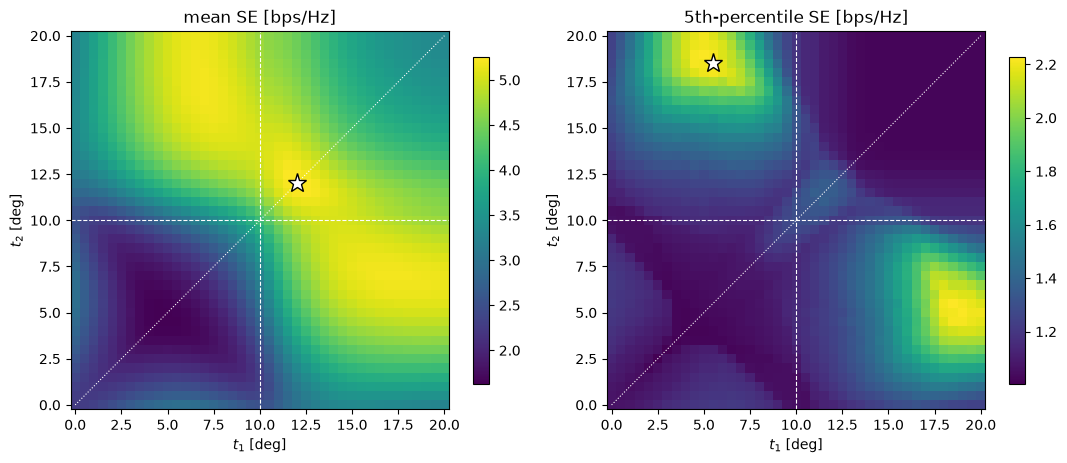

In [15]:
wide = tilt_sweep(sectors, [EXPLORE, EXPLORE])
w_mean, w_p5 = wide["mean_se"], wide["p5_se"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, J, name in zip(axes, [w_mean, w_p5], ["mean SE [bps/Hz]", "5th-percentile SE [bps/Hz]"]):
    fig.colorbar(tilt_heatmap(ax, EXPLORE, EXPLORE, J, name), ax=ax, shrink=0.8)
    ax.axvline(10.0, color="white", lw=0.8, ls="--"); ax.axhline(10.0, color="white", lw=0.8, ls="--")
plt.tight_layout(); plt.show()

In [16]:
im = np.unravel_index(np.argmax(w_mean), w_mean.shape)
ip = np.unravel_index(np.argmax(w_p5), w_p5.shape)
print(f"mean-SE optimum   ({EXPLORE[im[0]]}, {EXPLORE[im[1]]}): mean {w_mean[im]:.3f}, 5th-pct {w_p5[im]:.3f}")
print(f"5th-pct optimum   ({EXPLORE[ip[0]]}, {EXPLORE[ip[1]]}): mean {w_mean[ip]:.3f}, 5th-pct {w_p5[ip]:.3f}")
print(f"cost of the mean optimum on the 5th-pct objective: {w_p5[im] / w_p5[ip] - 1:+.1%};  cost of the 5th-pct optimum on mean SE: {w_mean[ip] / w_mean[im] - 1:+.1%}")
half_w = np.triu(np.ones(w_mean.shape, dtype=bool))
front_w = non_dominated(w_mean[half_w], w_p5[half_w])
iw, jw = np.nonzero(half_w)
print(f"{front_w.sum()} non-dominated pairs of {front_w.size} (t1 <= t2):")
for k in np.nonzero(front_w)[0]:
    print(f"   ({EXPLORE[iw[k]]:4.1f}, {EXPLORE[jw[k]]:4.1f})  mean {w_mean[iw[k], jw[k]]:.3f}  5th-pct {w_p5[iw[k], jw[k]]:.3f}")
f_opt = sinr_field(wide["x"], wide["y"], sectors, [EXPLORE[ip[0]], EXPLORE[ip[1]]], params=p)
ww = wide["weights"] / wide["weights"].sum()
print(f"at the 5th-pct optimum sector 1 serves {ww[f_opt['serving'] == 0].sum():.1%} of the demand-weighted area, sector 2 serves {ww[f_opt['serving'] == 1].sum():.1%}")

mean-SE optimum   (12.0, 12.0): mean 5.257, 5th-pct 1.351
5th-pct optimum   (5.5, 18.5): mean 5.100, 5th-pct 2.228
cost of the mean optimum on the 5th-pct objective: -39.4%;  cost of the 5th-pct optimum on mean SE: -3.0%
9 non-dominated pairs of 861 (t1 <= t2):
   ( 5.5, 18.5)  mean 5.100  5th-pct 2.228
   ( 6.0, 18.0)  mean 5.153  5th-pct 2.181
   ( 6.0, 18.5)  mean 5.152  5th-pct 2.182
   ( 6.5, 17.5)  mean 5.183  5th-pct 2.125
   ( 6.5, 18.0)  mean 5.182  5th-pct 2.152
   ( 7.0, 17.0)  mean 5.191  5th-pct 2.009
   ( 7.0, 17.5)  mean 5.191  5th-pct 2.104
   (11.5, 12.0)  mean 5.224  5th-pct 1.361
   (12.0, 12.0)  mean 5.257  5th-pct 1.351
at the 5th-pct optimum sector 1 serves 89.7% of the demand-weighted area, sector 2 serves 10.3%


In [17]:
print("exploration range, one variable at a time:")
for label, kw in [("grid 50 x 50", dict(nx=50, ny=50)), ("grid 100 x 100 (baseline)", dict()), ("grid 200 x 200", dict(nx=200, ny=200)),
                  ("y half-width 150 m", dict(y_range=(-150, 150), ny=60)), ("y half-width 400 m", dict(y_range=(-400, 400), ny=160))]:
    s = tilt_sweep(sectors, [EXPLORE, EXPLORE], **kw)
    im = np.unravel_index(s["mean_se"].argmax(), s["mean_se"].shape); ip = np.unravel_index(s["p5_se"].argmax(), s["p5_se"].shape)
    print(f"  {label:26s} mean optimum ({EXPLORE[im[0]]:4.1f}, {EXPLORE[im[1]]:4.1f}) mean {s['mean_se'][im]:.3f} p5 {s['p5_se'][im]:.3f} | "
          f"5th-pct optimum ({EXPLORE[ip[0]]:4.1f}, {EXPLORE[ip[1]]:4.1f}) mean {s['mean_se'][ip]:.3f} p5 {s['p5_se'][ip]:.3f}")

exploration range, one variable at a time:
  grid 50 x 50               mean optimum (12.0, 12.0) mean 5.274 p5 1.287 | 5th-pct optimum ( 4.5, 18.5) mean 4.930 p5 2.252
  grid 100 x 100 (baseline)  mean optimum (12.0, 12.0) mean 5.257 p5 1.351 | 5th-pct optimum ( 5.5, 18.5) mean 5.100 p5 2.228
  grid 200 x 200             mean optimum (12.0, 12.0) mean 5.258 p5 1.341 | 5th-pct optimum ( 5.0, 19.0) mean 5.022 p5 2.222
  y half-width 150 m         mean optimum (12.5, 12.5) mean 6.818 p5 1.622 | 5th-pct optimum ( 5.5, 19.0) mean 5.086 p5 1.801
  y half-width 400 m         mean optimum (18.5,  5.5) mean 5.030 p5 2.491 | 5th-pct optimum ( 5.0, 19.0) mean 5.025 p5 2.508


**Reading the exploration** (model-exploration range, same region and demand).

- **The mean-SE optimum is the equal-tilt pair $(12°,12°)$** (5.26 bps/Hz) — beyond the interval, and
  stable under grid refinement.
- **The 5th-percentile optimum on the sampled 0.5° grid is the strongly unequal pair $(5.5°,18.5°)$** — the
  best *sampled* angle, not a located peak: it is one point along a flat ridge (see Stability and Section
  6b). Its 5th-percentile SE is 2.23 bps/Hz against 1.35 at the mean optimum, while costing only $3.0\,\%$
  of mean SE. Using the mean-optimal pair on the 5th-percentile objective costs $39\,\%$. The lower-tail gain is not a
  coarse-grid effect: on the $200\times200$ grid $(5.5°,18.5°)$ gives 2.21 against 1.34 bps/Hz at $(12°,12°)$. Its mirror twin
  $(18.5°,5.5°)$ has identical values, as the symmetry requires. This supports **H1's second part** in this
  range.
- **The objectives now disagree:** 9 pairs are non-dominated, so there is a genuine trade-off, between
  $(12°,12°)$ and the unequal pairs near $(5.5°\!-\!7°,\,17°\!-\!18.5°)$.
- **What the unequal optimum is, physically.** At 18.5° the steep sector's beam lands about
  $28.5/\tan 18.5^\circ\approx85$ m from its mast and, by the floor-edge formula of 2a, it sits on its
  $-17$ dB elevation floor for points farther than about 150 m from its mast. Measured by distance from that
  mast (not by x-extent), about 86 % of the weighted area is farther than 150 m, and the floor condition
  holds on about 88 % of it. Sector 1 serves 89.7 % of the area. So the steep sector acts as a small cell next
  to its mast and sector 1 covers the rest. This does **not** mean interference is small: at $(5.5°,18.5°)$
  the I/N is at least 15.7 dB everywhere, and the signal-to-interference ratio is 5.7 / 15.8 / 22.2 dB at
  the 5th / 50th / 95th percentile. The gain comes from a *wide power ratio*, not from absent interference.
- **Caveats.** (i) Beyond the baseline 0–10° interval. (ii) It leans on the constant elevation-floor
  approximation of the pattern, the kind of regime flagged in L01; Section 6b varies the floor level and
  shows that the location of the optimum depends on it. (iii) The metrics reward this configuration under *uniform* demand; whether it survives realistic demand is
  OQ11. (iv) **Load:** one sector serves about 90 % of the area, so under uniform demand it would carry about
  nine times the demand of the other. Mean SE is a per-link figure, not network capacity: it says nothing about
  how much of a sector's resources each user receives. Whether the advantage survives resource sharing remains
  untested.
- **Stability.** Along the ridge the exact angles are not determined: the best sampled 5th-percentile pair
  moves between $(4.5°,18.5°)$, $(5.5°,18.5°)$ and $(5°,19°)$ across grids, and between $(5.5°,19°)$ at
  $a=150$ m and $(5°,19°)$ at $a=400$ m; its value is 2.22–2.25 bps/Hz across grids. At $a=400$ m the mean
  optimum itself becomes the unequal pair $(18.5°,5.5°)$. Section 6b shows that the *advantage* of the
  unequal pair over equal tilts also depends strongly on the region, so "an equal-tilt optimum for the mean
  and an unequal ridge for the 5th percentile" holds for the baseline region and the $-17$ dB floor, not
  universally.


## 6b. Is the unequal optimum an artefact? Fixed candidates and the elevation floor

Two different questions hide behind "the optimum moved". A *numerical* artefact would show as a ranking that
changes with the grid at a fixed region. A *model* or *scenario* dependence would show as a ranking that
changes when the region or the antenna-pattern floor changes. To separate them, fix a handful of candidate
pairs and evaluate **the same pairs** on every grid and region (instead of re-locating the argmax each time),
then repeat the exploration sweep with the elevation floor $\mathrm{SLL}_{\mathrm{el}}$ set to different
levels. One variable changes per row; $-17$ dB is the [E] Table I value, the others are assumptions.

In [18]:
CAND = [(8.0, 8.0), (10.0, 10.0), (12.0, 12.0), (5.5, 18.5), (5.0, 19.0), (4.5, 18.5)]
T_CAND = np.array(sorted({t for pair in CAND for t in pair}))
print("fixed candidate pairs, mean SE / 5th-pct SE (bps/Hz):")
for label, kw in [("grid 50 x 50", dict(nx=50, ny=50)), ("grid 100 x 100 (baseline)", dict()), ("grid 200 x 200", dict(nx=200, ny=200)),
                  ("y half-width 125 m", dict(y_range=(-125, 125), ny=50)), ("y half-width 400 m", dict(y_range=(-400, 400), ny=160)),
                  ("y half-width 500 m", dict(y_range=(-500, 500), ny=200))]:
    s = tilt_sweep(sectors, [T_CAND, T_CAND], **kw)
    cells = []
    for a, b in CAND:
        i, j = np.flatnonzero(T_CAND == a)[0], np.flatnonzero(T_CAND == b)[0]
        cells.append(f"({a:g},{b:g}) {s['mean_se'][i, j]:.2f}/{s['p5_se'][i, j]:.2f}")
    print(f"  {label:26s} " + "  ".join(cells))

fixed candidate pairs, mean SE / 5th-pct SE (bps/Hz):
  grid 50 x 50               (8,8) 2.65/1.12  (10,10) 4.10/1.26  (12,12) 5.27/1.29  (5.5,18.5) 5.11/2.15  (5,19) 5.03/2.21  (4.5,18.5) 4.93/2.25
  grid 100 x 100 (baseline)  (8,8) 2.64/1.12  (10,10) 4.09/1.29  (12,12) 5.26/1.35  (5.5,18.5) 5.10/2.23  (5,19) 5.02/2.22  (4.5,18.5) 4.92/2.21
  grid 200 x 200             (8,8) 2.64/1.11  (10,10) 4.09/1.29  (12,12) 5.26/1.34  (5.5,18.5) 5.10/2.21  (5,19) 5.02/2.22  (4.5,18.5) 4.92/2.21
  y half-width 125 m         (8,8) 3.25/1.17  (10,10) 5.13/1.47  (12,12) 6.99/1.61  (5.5,18.5) 5.16/1.65  (5,19) 5.03/1.69  (4.5,18.5) 4.90/1.62
  y half-width 400 m         (8,8) 2.13/1.02  (10,10) 3.03/1.01  (12,12) 3.73/1.02  (5.5,18.5) 5.03/2.49  (5,19) 5.03/2.51  (4.5,18.5) 4.99/2.47
  y half-width 500 m         (8,8) 2.04/1.02  (10,10) 2.67/1.00  (12,12) 3.22/1.01  (5.5,18.5) 4.89/2.34  (5,19) 4.93/2.40  (4.5,18.5) 4.93/2.41


In [19]:
from dataclasses import replace
print("elevation-floor level (SLL_el) varied, exploration range, baseline region:")
for sll in (-17.0, -20.0, -25.0, -30.0):
    s = tilt_sweep(sectors, [EXPLORE, EXPLORE], params=replace(p, sll_el=sll))
    im = np.unravel_index(s["mean_se"].argmax(), s["mean_se"].shape); ip = np.unravel_index(s["p5_se"].argmax(), s["p5_se"].shape)
    eq = np.diag(s["p5_se"]); k = int(np.argmax(eq))
    print(f"  SLL_el {sll:5.1f} dB: 5th-pct optimum ({EXPLORE[ip[0]]:4.1f}, {EXPLORE[ip[1]]:4.1f}) p5 {s['p5_se'][ip]:.3f} | "
          f"mean optimum ({EXPLORE[im[0]]:4.1f}, {EXPLORE[im[1]]:4.1f}) mean {s['mean_se'][im]:.3f} | "
          f"best equal-tilt p5 {eq[k]:.3f} at {EXPLORE[k]:.1f}")

elevation-floor level (SLL_el) varied, exploration range, baseline region:
  SLL_el -17.0 dB: 5th-pct optimum ( 5.5, 18.5) p5 2.228 | mean optimum (12.0, 12.0) mean 5.257 | best equal-tilt p5 1.355 at 11.5
  SLL_el -20.0 dB: 5th-pct optimum ( 4.5, 20.0) p5 2.645 | mean optimum ( 7.0, 18.5) mean 5.863 | best equal-tilt p5 1.402 at 12.5
  SLL_el -25.0 dB: 5th-pct optimum ( 4.0, 20.0) p5 2.725 | mean optimum (20.0,  6.5) mean 6.938 | best equal-tilt p5 1.438 at 13.5
  SLL_el -30.0 dB: 5th-pct optimum ( 5.0, 20.0) p5 2.660 | mean optimum ( 6.5, 20.0) mean 7.602 | best equal-tilt p5 1.438 at 13.5


**Reading the checks.**

- **Numerical vs model dependence.** Across grids (50², 100², 200²) the mean SE of every fixed candidate
  changes by under 2 %. The 5th percentile moves more (for $(12°,12°)$: 1.29, 1.35, 1.34), yet by an order of
  magnitude less than the unequal advantage: on the $200^2$ grid $(5.5°,18.5°)$ gives 2.21 against 1.34 at
  $(12°,12°)$. $(5.5°,18.5°)$ and $(5°,19°)$ trade places on the 5th percentile (2.228 against 2.222 at $100^2$,
  2.211 against 2.222 at $200^2$): a tie on a flat ridge, not a ranking. The region changes the answer far more
  than the grid does.
- **Scenario dependence (region).** At $a=250$ m the unequal pairs reach a 5th-percentile SE of about 2.2
  against 1.3 for the equal pairs $(10°,10°)$ and $(12°,12°)$. At $a=400$ m and $500$ m the unequal pairs
  stay at about 2.3–2.5 while the equal pairs fall to about 1.0. At $a=125$ m the lower-tail advantage
  **shrinks to almost nothing**: $(12°,12°)$ gives 1.61 against 1.62–1.69 for the unequal pairs (0.6–5 % higher),
  while the unequal pairs lose about 26–30 % of the mean SE (4.90–5.16 against 6.99). What changes
  dramatically is the trade-off, not only the size of the gain. The unequal-tilt result is therefore a result
  for a strip that is wide relative to the site spacing.
- **Model dependence (floor).** The unequal ridge survives every floor level tested — the best unequal pair has
  a 5th-percentile SE of about 2.2–2.7 against 1.35–1.44 for the best equal pair — but its *location* moves:
  at $-17$ dB the optimum is interior, $(5.5°,18.5°)$; at $-20$, $-25$ and $-30$ dB the steep sector goes to
  the 20° edge of the exploration range, so the range itself is limiting. At $-20$ dB and below the *mean*
  optimum becomes unequal as well ($(7°,18.5°)$ at $-20$ dB; $(6.5°,20°)$ or its mirror twin at $-25$ and
  $-30$ dB). The statement "equal for the mean, unequal for the 5th percentile" holds at the Table I floor only.
- **What this does and does not establish.** "Unequal tilts beat equal tilts on lower-tail link SE" is stable
  under grid refinement and survives the floor levels tested, but its size, its exact angles and — for narrow
  regions — its practical value depend on the observation region and on the floor. Varying the level tests
  one parameter, not the floor approximation itself: every run keeps a constant clipped floor, so this is not
  evidence of robustness to antenna-pattern modelling in general.


## 6c. Who benefits? The two strategies on the ground

The heatmaps say which settings win; these maps show **where**. For the mean-optimal pair $(12°,12°)$ and the
5th-percentile-optimal pair $(5.5°,18.5°)$ they show which sector serves each location, the spectral efficiency on
one common colour scale, and the locations belonging to the worst 5 % of the demand-weighted area. The weighted
cumulative distribution that follows turns the 5th percentile into the point where each curve reaches 5 %.

(12°, 12°): best mean: worst-5 % cells at 248-365 m from sector 2 (5th-95th pct), x 228-272 m; 50.0% served by sector 1; 100.0% within 3 dB of equal power
(5.5°, 18.5°): best 5th percentile: worst-5 % cells at 98-157 m from sector 2 (5th-95th pct), x 348-492 m; 56.7% served by sector 1; 43.7% within 3 dB of equal power


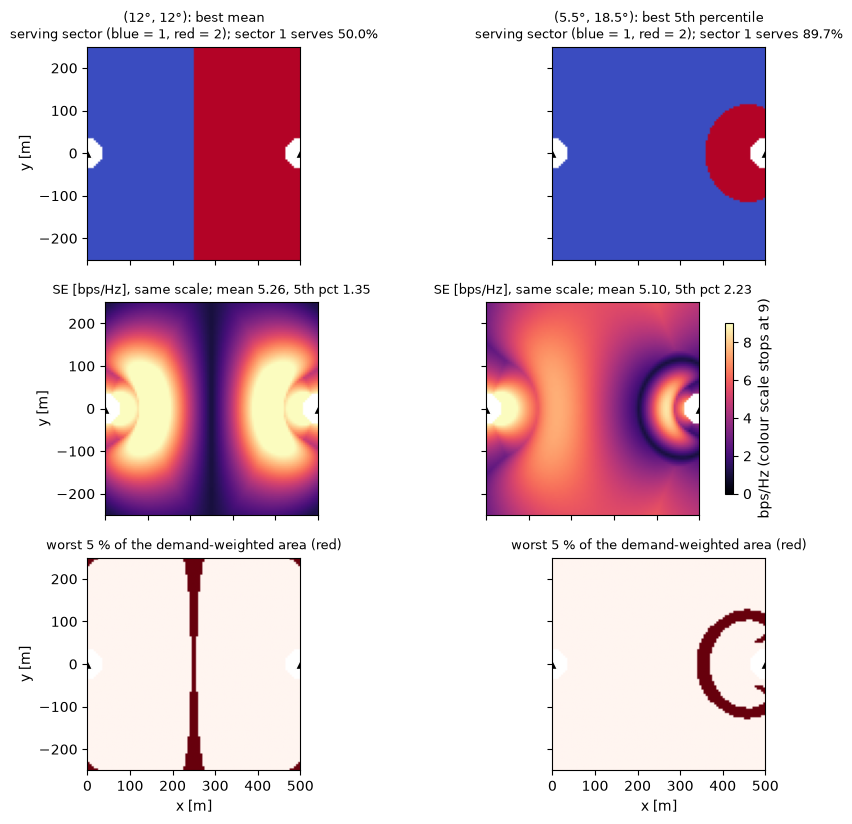

In [20]:
CASES = [("(12°, 12°): best mean", (12.0, 12.0)), ("(5.5°, 18.5°): best 5th percentile", (5.5, 18.5))]
fig, axes = plt.subplots(3, 2, figsize=(11, 9.4), sharex=True, sharey=True)
for col, (label, tilts) in enumerate(CASES):
    f_c = sinr_field(base["x"], base["y"], sectors, list(tilts), params=p)
    p5_c = weighted_percentile(f_c["se"], base["weights"], 5.0)
    low = (f_c["se"] <= p5_c) & valid                                  # the worst 5 % of the demand-weighted area
    field_map(axes[0, col], f_c["serving"], NX, NY, EXTENT, valid, MASTS, cmap="coolwarm", vmin=0, vmax=1)
    axes[0, col].set_title(f"{label}\nserving sector (blue = 1, red = 2); sector 1 serves {wg[f_c['serving'] == 0].sum():.1%}", fontsize=9)
    im = field_map(axes[1, col], f_c["se"], NX, NY, EXTENT, valid, MASTS, cmap="magma", vmin=0, vmax=9)
    axes[1, col].set_title(f"SE [bps/Hz], same scale; mean {np.sum(wg * f_c['se']):.2f}, 5th pct {p5_c:.2f}", fontsize=9)
    field_map(axes[2, col], low, NX, NY, EXTENT, valid, MASTS, cmap="Reds", vmin=0, vmax=1)
    axes[2, col].set_title("worst 5 % of the demand-weighted area (red)", fontsize=9)
    gap = np.abs(to_db(f_c["powers"][0]) - to_db(f_c["powers"][1]))
    print(f"{label}: worst-5 % cells at {np.percentile(np.hypot(base['x'][low] - ISD, base['y'][low]), 5):.0f}-"
          f"{np.percentile(np.hypot(base['x'][low] - ISD, base['y'][low]), 95):.0f} m from sector 2 (5th-95th pct), "
          f"x {np.percentile(base['x'][low], 5):.0f}-{np.percentile(base['x'][low], 95):.0f} m; {np.mean(f_c['serving'][low] == 0):.1%} served by sector 1; "
          f"{np.mean(gap[low] < 3.0):.1%} within 3 dB of equal power")
for ax in axes[2, :]: ax.set_xlabel("x [m]")
for ax in axes[:, 0]: ax.set_ylabel("y [m]")
fig.colorbar(im, ax=axes[1, :], shrink=0.8, pad=0.03, label="bps/Hz (colour scale stops at 9)")
plt.show()

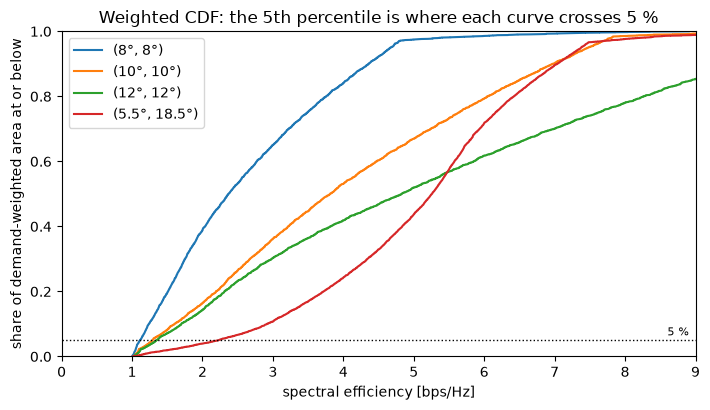

In [21]:
fig, ax = plt.subplots(figsize=(7.2, 4.2))
for tilts in [(8.0, 8.0), (10.0, 10.0), (12.0, 12.0), (5.5, 18.5)]:
    se_c = sinr_field(base["x"], base["y"], sectors, list(tilts), params=p)["se"]
    ax.plot(*weighted_cdf(se_c[valid], base["weights"][valid]), label=f"({tilts[0]:g}°, {tilts[1]:g}°)")
ax.axhline(0.05, color="k", ls=":", lw=1); ax.text(8.9, 0.065, "5 %", ha="right", fontsize=8)
ax.set(xlabel="spectral efficiency [bps/Hz]", ylabel="share of demand-weighted area at or below", xlim=(0, 9), ylim=(0, 1),
       title="Weighted CDF: the 5th percentile is where each curve crosses 5 %")
ax.legend(); plt.tight_layout(); plt.show()

**Reading the maps and the CDF.**

- **$(12°,12°)$: a symmetric split.** Each sector serves its half, the SE is high in a lobe around each mast, and
  it falls to about 1 bps/Hz along the tie line, where the two powers are equal. Most of the worst-5 % locations
  form a central strip (the middle 90 % of them have $x$ between 228 and 272 m); smaller patches also occur near
  the outer corners, where both sectors are weak (about 9 % of the tail weight lies outside $|x-250|\le25$ m).
  All of them lie within 3 dB of equal power.
- **$(5.5°,18.5°)$: one sector dominates.** Sector 1 serves 89.7 % of the area; sector 2 serves a disc of
  roughly 115–140 m radius around its mast. The SE is high across most of the strip, with a dark arc around
  that disc. The worst 5 % lies mainly on that arc: the middle 90 % of those locations are 98–157 m from sector 2
  (all of them 53–161 m). Only 43.7 % of them have powers within 3 dB of each other, so not every tail location
  is at near-equal power. The low-quality region follows the steep sector's footprint boundary and extends into
  neighbouring locations where the power imbalance remains modest. A supported interpretation, not a separately
  isolated mechanism: those locations sit where the steep sector's signal is already falling onto its $-17$ dB
  floor (onset ≈150 m) while sector 1 is still far away.
- **The CDF.** For a CDF $F(c)=\Pr(C\le c)$, a lower curve means less demand below the threshold. At the 5 %
  line the unequal pair's curve sits well to the right (2.23 against 1.35 bps/Hz for $(12°,12°)$). For thresholds
  below the crossing near 5.4 bps/Hz, the unequal configuration generally has less demand below the threshold —
  for example, about 89 % exceeds 3 bps/Hz, against 70 % with equal tilts. At higher thresholds the equal
  configuration provides more exceptionally strong links (30 % above 7 bps/Hz, against 10 %). Neither
  configuration is better at every threshold.
- **What this explains.** Equal tilts give very strong links over substantial areas near both masts but leave
  weak locations around the middle. Unequal tilts redistribute that quality: fewer exceptionally strong links,
  better quality over much of the region and a better lower tail, and a smaller service footprint for the steeply
  tilted sector. "The optimal tilt" is therefore incomplete until the objective and the demand are specified
  (Section 5, OQ11).


## 7. Served fraction (OQ10)

OQ10 predicted that the served fraction at $\gamma=1$ bps/Hz is near-saturated by construction (with two
sectors, $\mathrm{SE}\ge1\iff S_{\max}\ge S_{\min}+N$) and that a stricter bar could discriminate. Here the
served fraction is a **demand-weighted sum over cells**, $\sum_i p_i\,\mathbf 1\{C_i\ge\gamma\}$, never a count
of map pixels. $\gamma=2$ bps/Hz corresponds to $\mathrm{SINR}\ge3$ (4.8 dB); $\gamma=3$ is shown for
comparison. The choice of $\gamma$ is a modelling choice.

gamma = 1 bps/Hz: served fraction ranges 0.9974 to 1.0000 over the 441 pairs; best at (0.0, 0.0); at (8,8) 1.0000
gamma = 2 bps/Hz: served fraction ranges 0.1703 to 0.8367 over the 441 pairs; best at (10.0, 10.0); at (8,8) 0.6128
gamma = 3 bps/Hz: served fraction ranges 0.0372 to 0.6375 over the 441 pairs; best at (10.0, 10.0); at (8,8) 0.3499


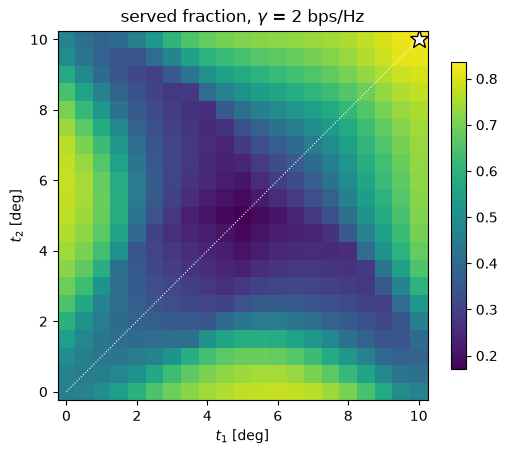

In [22]:
w_all = base["weights"] / base["weights"].sum()
for gamma in (1.0, 2.0, 3.0):
    sf = (base["cube"] >= gamma) @ w_all                   # demand-weighted share of the area with SE >= gamma
    i, j = np.unravel_index(np.argmax(sf), sf.shape)
    print(f"gamma = {gamma:.0f} bps/Hz: served fraction ranges {sf.min():.4f} to {sf.max():.4f} over the 441 pairs; best at ({FEASIBLE[i]}, {FEASIBLE[j]}); at (8,8) {sf[16, 16]:.4f}")
sf2 = (base["cube"] >= 2.0) @ w_all
fig, ax = plt.subplots(figsize=(5.4, 4.6))
fig.colorbar(tilt_heatmap(ax, FEASIBLE, FEASIBLE, sf2, "served fraction, $\\gamma$ = 2 bps/Hz"), ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

**Reading the table.** At $\gamma=1$ the served fraction is between 0.9974 and 1.0000 over all 441 pairs — it
has almost no discrimination, as OQ10 predicted. At $\gamma=2$ it ranges from 0.17 to 0.84 and is largest at
$(10°,10°)$; at $(8°,8°)$ it is 0.61. $\gamma=3$ has the same sampled maximiser (0.04–0.64 over the pairs;
the full rankings were not compared). So **a stricter bar makes the served fraction discriminate**, and
inside the baseline interval its sampled maximiser agrees with the other two objectives. The $\gamma=2$ value
at $(10°,10°)$ is stable under grid refinement (0.8363, 0.8367, 0.8348 for 50², 100², 200² cells; Section 5).


## 8. Summary and limits

**What was shown** (deterministic, median link; this layout, region, uniform demand, grid and tilt step).

1. $J(t_1,t_2)=J(t_2,t_1)$ holds to $10^{-15}$ for both objectives.
2. Inside the baseline interval (0–10°) both objectives and the $\gamma=2$ served fraction peak at
   $(10°,10°)$, the edge. The optimum is constraint-active, steep rather than a plateau, and there is no
   trade-off between the objectives.
3. Raising both tilts widens the absolute power gap $|\Delta_{\mathrm{dB}}|$ only where
   $\operatorname{sgn}(\Delta_{\mathrm{dB}})(\beta_1-\beta_2)>0$, at rate $24|\beta_1-\beta_2|/\mathrm{HPBW}^2$ dB/°
   (verified on the axis and over the map; over a finite step $\Delta_b=\Delta_a+kh$ holds exactly on unclipped cells,
   and the gap widens everywhere for 8°→10° but on only 66 % of the unclipped area for 4°→5°). At
   $(10°,10°)$ the worst 5 % is a strip about 45 m wide around the tie line (H2, at that pair only).
4. The results are stable under grid refinement; they are **not** insensitive to the region: at a half-width of
   400 m the optima leave the equal-tilt corner.
5. Beyond the assumed interval (exploration range, baseline region, $-17$ dB floor) the mean optimum is
   $(12°,12°)$ and the best sampled 5th-percentile pair is $(5.5°,18.5°)$, one point of a flat unequal ridge;
   choosing it costs $3\,\%$ of mean SE and raises the 5th-percentile SE by $65\,\%$ (2.23 against 1.35
   bps/Hz).
6. The substantial lower-tail advantage persists under the tested grid refinements: on the $200\times200$ grid
   $(5.5°,18.5°)$ gives a 5th-percentile SE of 2.21 against 1.34 bps/Hz at $(12°,12°)$. Its size and the
   preferred angles depend on the observation region (the lower-tail gain shrinks to almost nothing at $a=125$ m,
   with a large mean-SE loss, and grows at $a=400$–500 m) and on the elevation-floor level (Section 6b).
7. Equal tilts concentrate the weakest locations in a central strip (with small corner patches); unequal tilts move
   them mainly to an arc around the steep sector's footprint (Section 6c). The CDFs cross near 5.4 bps/Hz: unequal
   tilts exchange some exceptionally strong links for better lower-tail quality.

**What was not shown.** Whether the advantage survives sector load and resource sharing (one sector serves about 90 % of the area
at the unequal optimum; mean SE is not network capacity), realistic demand (OQ11: deliberate hotspot cases, then a seeded ensemble), mechanical tilt (OQ3: a separate controlled comparison; relabelling the 0–20° electrical results would be
wrong, since the patterns differ off boresight), scheduling and resource sharing (user throughput
$\approx B f_u C_u$ needs the resource fraction $f_u$, which this study does not model), shadow fading and uncertainty (D06), other layouts,
and any quantum-versus-classical comparison.

**Conclusion.** For this baseline scenario (deterministic two-sector model, uniform demand), unequal tilts exchange
some exceptionally strong links for better lower-tail quality, at a modest mean-SE penalty. The advantage persists
under the tested spatial refinements, while its size and preferred settings depend on the observation region and
the antenna-floor parameters; robustness to other antenna-pattern assumptions, demand concentration and resource sharing remains to be
tested (the floor level has been varied in Section 6b; the floor approximation, demand and load have not).

**What we learned.** Tilt optimisation balances useful signal, interference and *who* benefits.
- An antenna can help the network by transmitting *less* strongly towards some locations: stronger received
  power everywhere is not the objective when other antennas interfere.
- Different metrics prefer different service footprints. Maximising the mean and raising the lower tail are
  separate choices, and neither is automatically the operational goal.
- The demand domain is part of the problem: widening the rectangle adds users in new places, so the answer
  changes.
- The optimiser exposes the model's assumptions: it finds its strongest solutions in the floor-dominated regime,
  which shows where model fidelity matters most.

**Where this leads.** For $N$ sectors the structure is the same, with $s(u)=\arg\max_j P_jg_{ju}$ and
$\mathrm{SINR}_u=P_{s(u)}g_{s(u)u}/(N_u+\sum_{j\ne s(u)}P_jg_{ju})$, aggregated over demand and subject to each
sector's permitted settings. The two-sector reading changes, though: one dominant server can still face a large
*sum* of weaker interferers, so a ratio to a single competitor no longer describes the problem. The planned
progression is: controlled demand hotspots with the present physics (next notebook); several sectors with
external interferers around the evaluation region; realistic geometry, orientations, patterns and feasible
tilt ranges; resource sharing and stochastic propagation, each introduced separately; and optimisation methods
checked against small exhaustive benchmarks and held-out demand scenarios. The moving-frame idea belongs on
this path: each local solve must account for users and interference outside its window, which is exactly what
the two-sector experiment shows. A general multi-sector SINR objective is not automatically a pairwise QUBO;
that approximation will need its own validation against the physical objective.
